In [ ]:
import pandas as pd


In [ ]:
df = pd.read_csv("/content/house_sales.csv")


In [ ]:
# Display the first 5 rows
print(df.head())

           id             date     price  bedrooms  bathrooms  sqft_living  \
0  7129300520  20141013T000000  221900.0         3       1.00         1180   
1  6414100192  20141209T000000  538000.0         3       2.25         2570   
2  5631500400  20150225T000000  180000.0         2       1.00          770   
3  2487200875  20141209T000000  604000.0         4       3.00         1960   
4  1954400510  20150218T000000  510000.0         3       2.00         1680   

   sqft_lot  floors  waterfront  view  ...  grade  sqft_above  sqft_basement  \
0      5650     1.0           0     0  ...      7        1180              0   
1      7242     2.0           0     0  ...      7        2170            400   
2     10000     1.0           0     0  ...      6         770              0   
3      5000     1.0           0     0  ...      7        1050            910   
4      8080     1.0           0     0  ...      8        1680              0   

   yr_built  yr_renovated  zipcode      lat     lo

In [ ]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

Dataset shape: (21613, 21)


In [ ]:
# Check column names and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  object 
 2   price          21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  int64  
 12  sqft_above     21613 non-null  int64  
 13  sqft_basement  21613 non-null  int64  
 14  yr_built       21613 non-null  int64  
 15  yr_renovated   21613 non-null  int64  
 16  zipcode        21613 non-null  int64  
 17  lat            21613 non-null  float64
 18  long  

In [ ]:
# Check missing values
print(df.isnull().sum())


id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64


In [ ]:
# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())


Duplicate rows: 0


In [ ]:
# Check basic statistics
print(df.describe().round(2))

                 id       price  bedrooms  bathrooms  sqft_living    sqft_lot  \
count  2.161300e+04    21613.00  21613.00   21613.00     21613.00    21613.00   
mean   4.580302e+09   540182.16      3.37       2.11      2079.90    15106.97   
std    2.876566e+09   367362.23      0.93       0.77       918.44    41420.51   
min    1.000102e+06    75000.00      0.00       0.00       290.00      520.00   
25%    2.123049e+09   321950.00      3.00       1.75      1427.00     5040.00   
50%    3.904930e+09   450000.00      3.00       2.25      1910.00     7618.00   
75%    7.308900e+09   645000.00      4.00       2.50      2550.00    10688.00   
max    9.900000e+09  7700000.00     33.00       8.00     13540.00  1651359.00   

         floors  waterfront      view  condition     grade  sqft_above  \
count  21613.00    21613.00  21613.00   21613.00  21613.00    21613.00   
mean       1.49        0.01      0.23       3.41      7.66     1788.39   
std        0.54        0.09      0.77       0.65

In [ ]:
# Convert the sale date to a proper date format
df['date'] = pd.to_datetime(
    df['date'],
    format='%Y%m%dT%H%M%S'
)


In [ ]:
# Display the date range
print("Earliest sale:", df['date'].min())
print("Latest sale:", df['date'].max())


Earliest sale: 2014-05-02 00:00:00
Latest sale: 2015-05-27 00:00:00


In [ ]:
# Check unusual values
print("Houses with zero bedrooms:",
      (df['bedrooms'] == 0).sum())


Houses with zero bedrooms: 13


In [ ]:
print("Houses with zero bathrooms:",
      (df['bathrooms'] == 0).sum())

Houses with zero bathrooms: 10


In [ ]:
print("Houses with zero price:",
      (df['price'] <= 0).sum())


Houses with zero price: 0


In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")


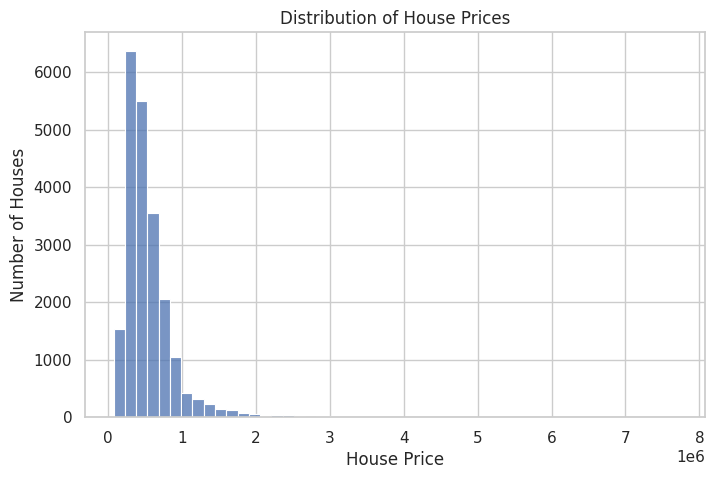

In [ ]:
#Understand the distribution of house prices
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='price', bins=50)

plt.title('Distribution of House Prices')
plt.xlabel('House Price')
plt.ylabel('Number of Houses')

plt.show()


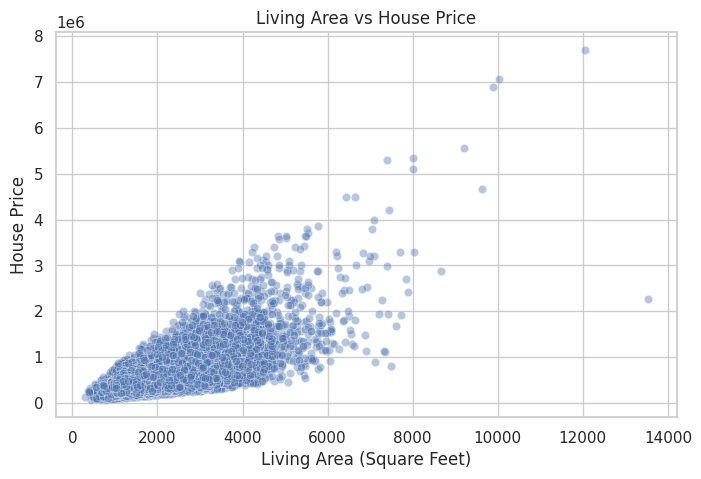

In [ ]:
#Check the relationship between living area and price
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='sqft_living',
    y='price',
    alpha=0.4
)

plt.title('Living Area vs House Price')
plt.xlabel('Living Area (Square Feet)')
plt.ylabel('House Price')

plt.show()


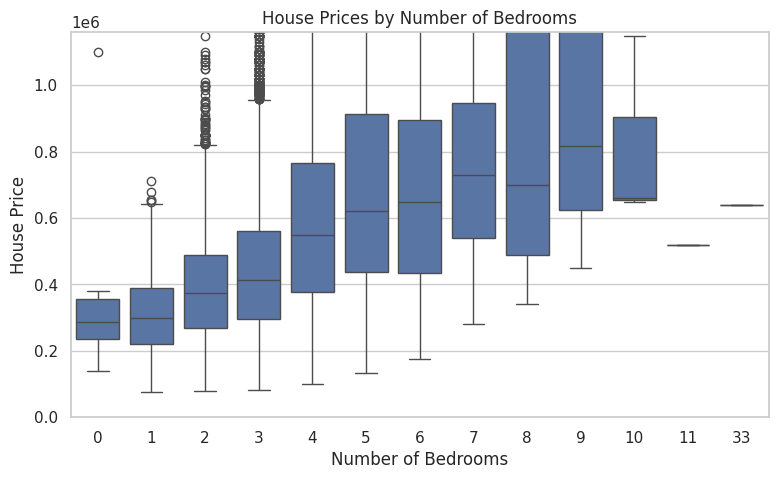

In [ ]:
#Compare prices by number of bedrooms
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='bedrooms',
    y='price'
)

plt.ylim(0, df['price'].quantile(0.95))

plt.title('House Prices by Number of Bedrooms')
plt.xlabel('Number of Bedrooms')
plt.ylabel('House Price')

plt.show()


In [ ]:
#Identify the strongest relationships with price
numeric_df = df.select_dtypes(include='number')

correlations = numeric_df.corr()['price'].sort_values(
    ascending=False
)

print(correlations)


price            1.000000
sqft_living      0.702044
grade            0.667463
sqft_above       0.605566
sqft_living15    0.585374
bathrooms        0.525134
view             0.397346
sqft_basement    0.323837
bedrooms         0.308338
lat              0.306919
waterfront       0.266331
floors           0.256786
yr_renovated     0.126442
sqft_lot         0.089655
sqft_lot15       0.082456
yr_built         0.053982
condition        0.036392
long             0.021571
id              -0.016797
zipcode         -0.053168
Name: price, dtype: float64


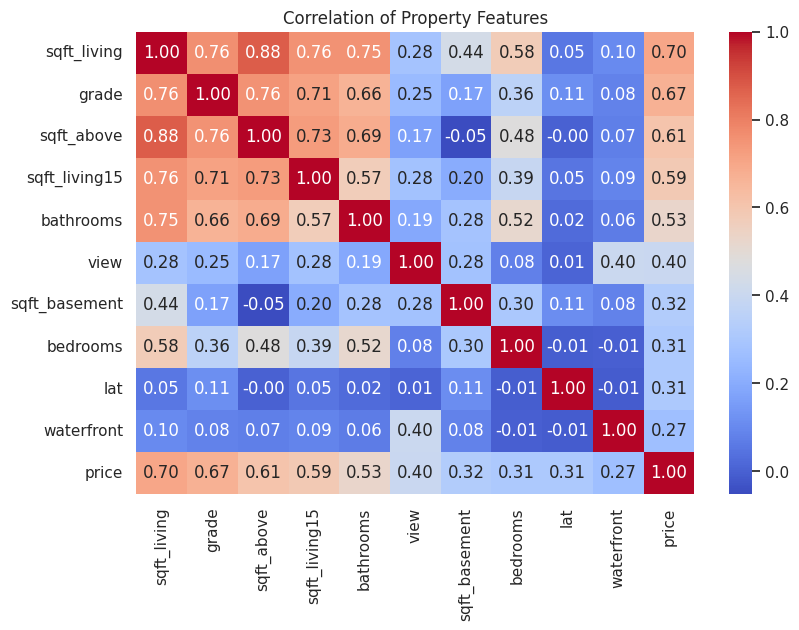

In [ ]:

top_features = correlations.drop('price').abs().nlargest(10).index

plt.figure(figsize=(9, 6))

sns.heatmap(
    df[list(top_features) + ['price']].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation of Property Features')
plt.show()
# for interpretation
#Correlation near +1: strong positive linear relationship.
#Correlation near -1: strong negative linear relationship.
#Correlation near 0: weak linear relationship.

In [ ]:
#Interpretation
#Larger living areas appear to be associated with higher house prices.
#Property quality may help explain differences in selling prices.
#House prices vary across locations.
#Some very expensive properties may behave differently from typical properties.

In [ ]:
# Convert the sale date into a standard date format
df['date'] = pd.to_datetime(
    df['date'],
    format='%Y%m%dT%H%M%S',
    errors='coerce'
)

# Save a cleaned CSV file for MySQL
df.to_csv(
    '/content/house_sales_cleaned.csv',
    index=False
)

print("Dataset saved successfully!")
print("Dataset shape:", df.shape)
print(df[['date', 'price']].head())

Dataset saved successfully!
Dataset shape: (21613, 21)
        date     price
0 2014-10-13  221900.0
1 2014-12-09  538000.0
2 2015-02-25  180000.0
3 2014-12-09  604000.0
4 2015-02-18  510000.0


In [ ]:
from google.colab import files

files.download('/content/house_sales_cleaned.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# Select input features for house price prediction
features = [
    'bedrooms',
    'bathrooms',
    'sqft_living',
    'sqft_lot',
    'floors',
    'waterfront',
    'view',
    'condition',
    'grade',
    'sqft_above',
    'sqft_basement',
    'yr_built',
    'yr_renovated',
    'lat',
    'long',
    'sqft_living15',
    'sqft_lot15'
]






In [ ]:
# X contains the input features
X = df[features]

In [ ]:
# y contains the house prices we want to predict
y = df['price']

print("Input features shape:", X.shape)
print("Target variable shape:", y.shape)

Input features shape: (21613, 17)
Target variable shape: (21613,)


In [ ]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])


Training records: 17290
Testing records: 4323


In [ ]:

from sklearn.linear_model import LinearRegression

# Create the model
model = LinearRegression()

# Train the model using training data
model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")


Linear Regression model trained successfully!


In [ ]:

# Predict prices for the testing data
y_pred = model.predict(X_test)

# Compare actual prices with predicted prices
comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred.round(2)
})

print(comparison.head(10))


   Actual Price  Predicted Price
0      365000.0        466592.68
1      865000.0        776318.08
2     1040000.0       1213287.49
3     1490000.0       1638677.25
4      711000.0        732406.75
5      211000.0        265091.85
6      790000.0        803122.70
7      680000.0        555367.81
8      384500.0        370411.14
9      605000.0        479112.69


Model Evaluation Results
------------------------
MAE: $128,272.93
RMSE: $214,595.34
R² Score: 0.6957


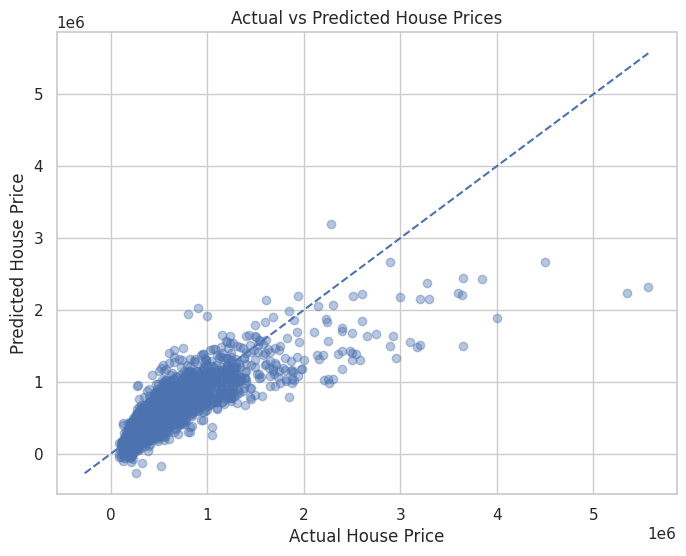

In [ ]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print(f"MAE: ${mae:,.2f}")
print(f"RMSE: ${rmse:,.2f}")
print(f"R² Score: {r2:.4f}")

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.4)

# Reference line for perfect predictions
min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle='--'
)

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted House Prices")
plt.show()


In [ ]:

# Export the dataset for Power BI
df.to_csv('/content/house_sales_powerbi.csv', index=False)

from google.colab import files
files.download('/content/house_sales_powerbi.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>